In [15]:
import torch
import pandas as pd
from pathlib import  Path

In [16]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

In [17]:
device

'cuda'

In [18]:
!nvidia-smi

Fri Oct 23 01:33:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.62                 KMD Version: 610.62        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4060 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   59C    P8              2W /  110W |     137MiB /   8188MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [19]:
from torch.utils.data import DataLoader,Dataset

In [20]:
# df = pd.read_csv("C:/Users/JAY/OneDrive/Desktop/Cheiron/Engine/data/train_hand_coordinates_dataset.csv")
csv_path = Path.cwd()/"data" / "train_hand_coordinates_dataset.csv"
df = pd.read_csv(csv_path)

In [21]:
df.head()

,label,x0,y0,z0,x1,y1,z1,x2,y2,z2,...,z17,x18,y18,z18,x19,y19,z19,x20,y20,z20
0,rock,0.668162,0.785275,-2.737996e-07,0.501973,0.664536,-0.006108,0.407591,0.547031,-0.031338,...,-0.034293,0.745313,0.328668,0.027748,0.707885,0.303582,0.099383,0.682476,0.310440,0.153926
1,rock,0.667716,0.785504,-2.862301e-07,0.501372,0.661910,0.003788,0.408754,0.544365,-0.018904,...,-0.038855,0.747881,0.330711,0.027895,0.710310,0.306879,0.102409,0.685591,0.313938,0.158159
2,rock,0.669007,0.790352,-3.610772e-07,0.501000,0.657790,0.018755,0.412298,0.538252,-0.002532,...,-0.055545,0.753332,0.335653,0.025360,0.719399,0.318367,0.107650,0.695720,0.330294,0.165670
3,rock,0.668644,0.789663,-3.381131e-07,0.507551,0.648194,0.016371,0.419295,0.538098,-0.019567,...,-0.105208,0.754383,0.330933,-0.027000,0.721816,0.323614,0.055389,0.695472,0.343122,0.110316
4,rock,0.667730,0.788152,-4.821687e-07,0.507336,0.639605,0.050666,0.423072,0.532465,0.028011,...,-0.125251,0.758160,0.328222,-0.046610,0.733736,0.332425,0.042978,0.720173,0.364126,0.104149


In [22]:
from sklearn.preprocessing import LabelEncoder


class HandCoordinatesDataset(Dataset):
    def __init__(self, dataframe):
        # 1. Store the dataframe and reset index to ensure sequential access
        self.data = dataframe.copy().reset_index(drop=True)
        
        # 2. Extract features (all columns except 'label')
        self.features = self.data.drop(columns=['label']).values
        
        # 3. Extract and encode labels
        self.label_encoder = LabelEncoder()
        self.labels = self.label_encoder.fit_transform(self.data['label'].values)
        
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        # 4. Convert specific row to PyTorch tensors
        features = torch.tensor(self.features[idx], dtype=torch.float32)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        
        return features, label

In [23]:
from sklearn.model_selection import train_test_split


train_df, test_df = train_test_split(
    df, 
    test_size=0.2, 
    random_state=42, 
    stratify=df['label'] # Crucial for balanced classes
)

In [24]:
train_dataset = HandCoordinatesDataset(train_df)
test_dataset = HandCoordinatesDataset(test_df)

In [25]:
train_loader = DataLoader(train_dataset, 
                            batch_size=32, 
                            shuffle=True,
                            num_workers=0)

test_loader = DataLoader(test_dataset,
                        batch_size=32, 
                        shuffle=False,
                        num_workers=0)

In [26]:
from model_and_loops.model import RPSModel

model = RPSModel().to(device)

In [27]:
loss_fn = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

In [28]:
from model_and_loops.loops_for_the_model import train_and_validate

hist = train_and_validate(
    train_loader =train_loader,  
    val_loader = test_loader,
    model=model,
    device=device,
    loss_fn=loss_fn, 
    optimizer=optimizer, 
    epochs=100)

In [30]:
hist

{'train_loss': [7.33430923860322e-05],
 'train_acc': [1.0],
 'val_loss': [0.00017239431033999608],
 'val_acc': [1.0]}

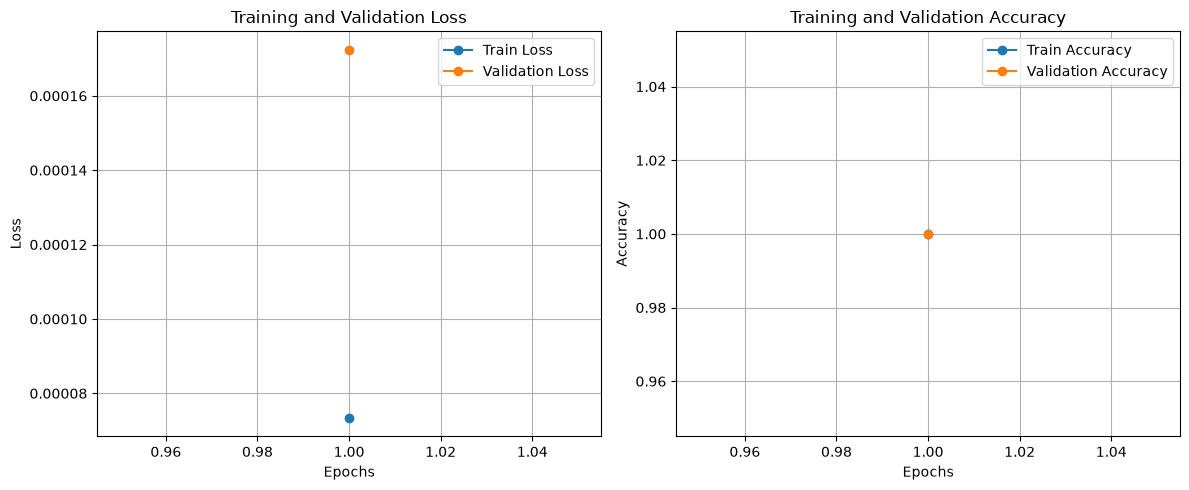

In [29]:
from model_and_loops.loops_for_the_model import plot_history

plot_history(hist)